# Dataset Analysis

P10 — Abstractive Summarisation of Hindi News


<!-- Cell purpose -->
**Cell purpose:** Placeholder for implementing this notebook section.

In [ ]:
# Purpose: Placeholder for implementing this notebook section.
# Add your implementation here.
!pip -q install datasets pandas numpy matplotlib seaborn networkx scikit-learn rouge-score tqdm

<!-- Cell purpose -->
**Cell purpose:** Import core libraries and verify the notebook environment.

In [ ]:
# Purpose: Import core libraries and verify the notebook environment.
import pandas as pd
import jinja2

print("Pandas:", pd.__version__)
print("Jinja2:", jinja2.__version__)
print("Imports successful!")


Pandas: 3.1.0
Jinja2: 3.1.6
Imports successful!


<!-- Cell purpose -->
**Cell purpose:** Install the Python packages required by this notebook.

In [ ]:
# Purpose: Install the Python packages required by this notebook.
!pip -q install pyarrow pandas jinja2

import pandas as pd

BASE = "https://huggingface.co/datasets/csebuetnlp/xlsum/resolve/651dcf16e996d411b12f0bb7b8fc671788f24193/hindi/"

files = {
    "train": "xlsum-train-00000-of-00002.parquet",
    "validation": "xlsum-validation.parquet",
    "test": "xlsum-test.parquet"
}

dataset = {}

for split, filename in files.items():
    dataset[split] = pd.read_parquet(BASE + filename)
    print(split, dataset[split].shape)

train (63000, 5)
validation (8847, 5)
test (8847, 5)


<!-- Cell purpose -->
**Cell purpose:** Display the dataset split sizes and sample records.

In [ ]:
# Purpose: Display the dataset split sizes and sample records.
print(dataset["train"].shape)
print(dataset["validation"].shape)
print(dataset["test"].shape)

display(dataset["test"].head())

(63000, 5)
(8847, 5)
(8847, 5)


,id,url,title,summary,text
0,081027_sadhvi_test_pp,https://www.bbc.com/hindi/regionalnews/story/2...,साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट,मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्व...,नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकव...
1,070929_pakistan_protest,https://www.bbc.com/hindi/regionalnews/story/2...,"मुशर्रफ़ का पर्चा मंज़ूर, प्रदर्शनों पर लाठी",पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रप...,इस बीच चुनाव आयोग ने शनिवार को राष्ट्रपति परवे...
2,international-45650689,https://www.bbc.com/hindi/international-45650689,इतनी जल्दी फ़्रांस में ही चमक क्यों खोने लगे र...,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान...,16 महीने के कार्यकाल पूरे होने के बावजूद राष्ट...
3,150415_iranian_nuclear_deal_public_humour_rns,https://www.bbc.com/hindi/international/2015/0...,'आइए व्हाइट हाउस में जुमे की नमाज़ पढ़ें',"""ओबामाः अब रिश्ते अच्छे हैं. आइए अब व्हाइट हाउ...","""या ख़ुदा! अब हम अमरीका आ जा सकते हैं! मैं पहन..."
4,040328_israel,https://www.bbc.com/hindi/news/story/2004/03/0...,इसराइल की ख़ुफ़िया एजेंसियों की खिंचाई,इसराइल में एक संसदीय रिपोर्ट में देश की ख़ुफ़ि...,इसराइल की ख़ुफ़िया एजेंसी मोसाद को दुनिया भर म...


<!-- Cell purpose -->
**Cell purpose:** Load the remaining training Parquet file and append it to the training split.

In [ ]:
# Purpose: Load the remaining training Parquet file and append it to the training split.
train2 = pd.read_parquet(
    BASE + "xlsum-train-00001-of-00002.parquet"
)

dataset["train"] = pd.concat(
    [dataset["train"], train2],
    ignore_index=True
)

print("Complete training set:", dataset["train"].shape)

Complete training set: (70778, 5)


<!-- Cell purpose -->
**Cell purpose:** Display the dataset split sizes and sample records.

In [ ]:
# Purpose: Display the dataset split sizes and sample records.
print("Train:", dataset["train"].shape)
print("Validation:", dataset["validation"].shape)
print("Test:", dataset["test"].shape)

print("\nColumns:", dataset["train"].columns.tolist())

Train: (70778, 5)
Validation: (8847, 5)
Test: (8847, 5)

Columns: ['id', 'url', 'title', 'summary', 'text']


<!-- Cell purpose -->
**Cell purpose:** Import core libraries and verify the notebook environment.

In [ ]:
# Purpose: Import core libraries and verify the notebook environment.
import pandas as pd
import numpy as np

train_df = dataset["train"].copy()

print("Dataset shape:", train_df.shape)

print("\nMissing values:")
print(train_df.isna().sum())

print("\nDuplicate complete rows:", train_df.duplicated().sum())

print("\nDuplicate article IDs:", train_df["id"].duplicated().sum())

print("\nEmpty articles:",
      train_df["text"].fillna("").str.strip().eq("").sum())

print("\nEmpty summaries:",
      train_df["summary"].fillna("").str.strip().eq("").sum())

Dataset shape: (70778, 5)

Missing values:
id         0
url        0
title      0
summary    0
text       0
dtype: int64

Duplicate complete rows: 0

Duplicate article IDs: 0

Empty articles: 0

Empty summaries: 1


<!-- Cell purpose -->
**Cell purpose:** Calculate and export summary statistics for article and summary lengths.

In [ ]:
# Purpose: Calculate and export summary statistics for article and summary lengths.
train_df["article_words"] = (
    train_df["text"].fillna("").str.split().str.len()
)

train_df["summary_words"] = (
    train_df["summary"].fillna("").str.split().str.len()
)

display(
    train_df[["article_words", "summary_words"]].describe().round(2)
)

,article_words,summary_words
count,70778.00,70778.00
mean,563.80,28.15
std,471.63,10.61
min,21.00,0.00
25%,261.00,21.00
50%,405.00,27.00
75%,714.00,33.00
max,10066.00,231.00


<!-- Cell purpose -->
**Cell purpose:** Plot the distributions of Hindi article and summary lengths.

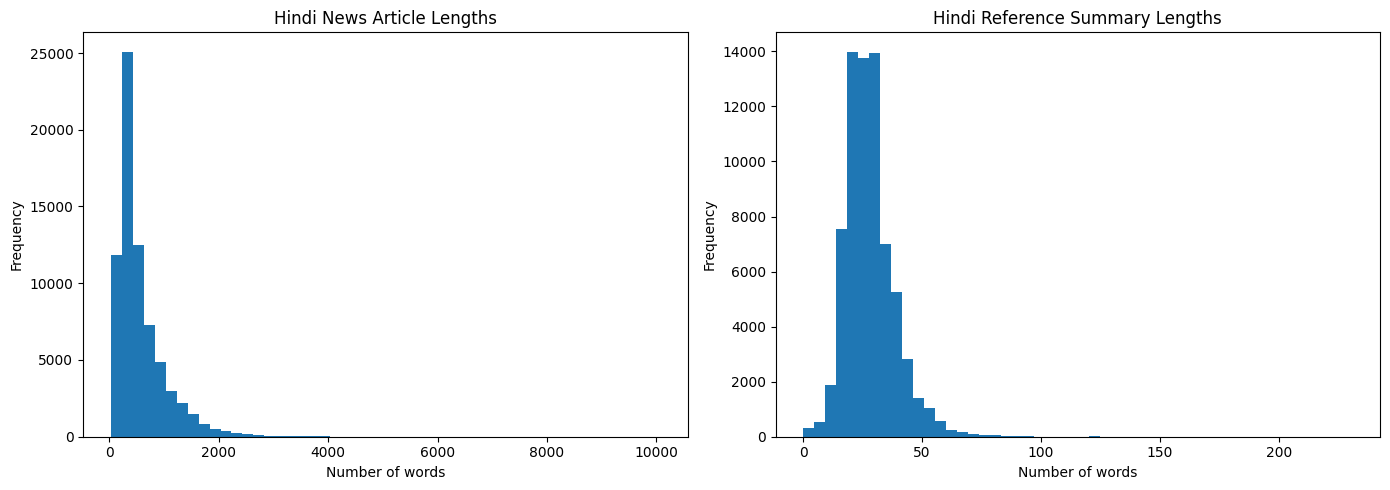

In [ ]:
# Purpose: Plot the distributions of Hindi article and summary lengths.
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_df["article_words"], bins=50)
axes[0].set_title("Hindi News Article Lengths")
axes[0].set_xlabel("Number of words")
axes[0].set_ylabel("Frequency")

axes[1].hist(train_df["summary_words"], bins=50)
axes[1].set_title("Hindi Reference Summary Lengths")
axes[1].set_xlabel("Number of words")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

<!-- Cell purpose -->
**Cell purpose:** Print representative articles alongside their reference summaries.

In [ ]:
# Purpose: Print representative articles alongside their reference summaries.
for i, row in train_df.head(5).iterrows():
    print("=" * 80)
    print("TITLE:", row["title"])
    print("\nARTICLE:\n", row["text"][:1200])
    print("\nREFERENCE SUMMARY:\n", row["summary"])

TITLE: चीन-नेपाल में गहराती दोस्ती पर इतना शांत क्यों है भारत

ARTICLE:
 नेपाल में इस दौरे की भरपूर तैयारियां चल रही हैं. इसकी ख़ास वजह भी है क्योंकि 23 साल बाद कोई चीनी राष्ट्रपति नेपाल पहुंच रहा है. नेपाल के प्रधानमंत्री केपी शर्मा ओली के विदेश मामलों के सलाहकार डॉ. राजन भट्टाराई ने इस दौरे को ऐतिहासिक बताया है. उन्होंने बताया कि चीन के राष्ट्रपति के साथ उनका एक प्रतिनिधि दल भी होगा. दोनों देशों के बीच कई समझौते होने की बात भी कही जा रही है. चीन के राष्ट्रपति और नेपाल के प्रधानमंत्री के बीच आधिकारिक बैठक भी तय हुई है. समाप्त नेपाल जाने से पहले चीन के राष्ट्रपति भारत में प्रधानमंत्री नरेंद्र मोदी के साथ अनौपचारिक मुलाक़ात करेंगे. इससे पहले शी जिनपिंग पाकिस्तान के प्रधानमंत्री इमरान ख़ान के साथ भी बैठक कर चुके हैं. चीन का प्रभाव दक्षिण एशिया में लगातार बढ़ रहा है. वो चाहे नेपाल, श्रीलंका, पाकिस्तान या बांग्लादेश हो. हर जगह चीन की मौजूदगी बढ़ी है. ये सभी देश चीन की वन बेल्ट वन रोड परियोजना में शामिल हो गए हैं. दूसरी तरफ़ भारत इस परियोजना के पक्ष में नहीं है. नेपाल की राष्ट्रपति विद्या द

<!-- Cell purpose -->
**Cell purpose:** Report the size, columns, and missing-value counts for every dataset split.

In [ ]:
# Purpose: Report the size, columns, and missing-value counts for every dataset split.
for split_name in ["train", "validation", "test"]:
    df = dataset[split_name].copy()

    print("=" * 50)
    print("Split:", split_name)
    print("Total records:", len(df))
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate article IDs:", df["id"].duplicated().sum())
    print("Empty articles:", df["text"].fillna("").str.strip().eq("").sum())
    print("Empty summaries:", df["summary"].fillna("").str.strip().eq("").sum())

Split: train
Total records: 70778
Duplicate rows: 0
Duplicate article IDs: 0
Empty articles: 0
Empty summaries: 1
Split: validation
Total records: 8847
Duplicate rows: 0
Duplicate article IDs: 0
Empty articles: 0
Empty summaries: 0
Split: test
Total records: 8847
Duplicate rows: 0
Duplicate article IDs: 0
Empty articles: 0
Empty summaries: 0


<!-- Cell purpose -->
**Cell purpose:** Calculate and export summary statistics for article and summary lengths.

In [ ]:
# Purpose: Calculate and export summary statistics for article and summary lengths.
for split_name in ["train", "validation", "test"]:
    df = dataset[split_name]

    df["title_words"] = df["title"].fillna("").str.split().str.len()
    df["article_words"] = df["text"].fillna("").str.split().str.len()
    df["summary_words"] = df["summary"].fillna("").str.split().str.len()

    print(f"\n{split_name.upper()} LENGTH STATISTICS")
    display(
        df[["title_words", "article_words", "summary_words"]]
        .describe()
        .round(2)
    )


TRAIN LENGTH STATISTICS


,title_words,article_words,summary_words
count,70778.00,70778.00,70778.00
mean,8.00,563.80,28.15
std,2.63,471.63,10.61
min,1.00,21.00,0.00
25%,6.00,261.00,21.00
50%,7.00,405.00,27.00
75%,9.00,714.00,33.00
max,27.00,10066.00,231.00



VALIDATION LENGTH STATISTICS


,title_words,article_words,summary_words
count,8847.00,8847.00,8847.00
mean,7.66,455.63,26.77
std,2.42,259.98,7.48
min,1.00,63.00,7.00
25%,6.00,257.00,21.00
50%,7.00,379.00,26.00
75%,9.00,588.00,32.00
max,22.00,1334.00,52.00



TEST LENGTH STATISTICS


,title_words,article_words,summary_words
count,8847.00,8847.00,8847.00
mean,7.70,457.95,26.71
std,2.43,262.09,7.37
min,2.00,75.00,9.00
25%,6.00,256.00,21.00
50%,7.00,375.00,26.00
75%,9.00,600.00,31.00
max,22.00,1359.00,52.00


<!-- Cell purpose -->
**Cell purpose:** Calculate the article-to-summary compression ratio.

In [ ]:
# Purpose: Calculate the article-to-summary compression ratio.
train_df["compression_ratio"] = (
    train_df["summary_words"] /
    train_df["article_words"].replace(0, np.nan)
)

print(
    "Mean compression ratio:",
    round(train_df["compression_ratio"].mean(), 4)
)

print(
    "Median compression ratio:",
    round(train_df["compression_ratio"].median(), 4)
)

Mean compression ratio: 0.0778
Median compression ratio: 0.0656


<!-- Cell purpose -->
**Cell purpose:** Import core libraries and verify the notebook environment.

In [ ]:
# Purpose: Import core libraries and verify the notebook environment.
import os

os.makedirs("/content/processed", exist_ok=True)

length_statistics = train_df[
    ["article_words", "summary_words"]
].describe()

length_statistics.to_csv(
    "/content/processed/length_statistics.csv"
)

print("Length statistics saved successfully.")

Length statistics saved successfully.


Part 3 — Generate predictions

<!-- Cell purpose -->
**Cell purpose:** Select the test split and preview its available columns and records.

In [ ]:
# Purpose: Select the test split and preview its available columns and records.
test_df = dataset["test"].copy()

print("Test set size:", len(test_df))
print("Columns:", test_df.columns.tolist())

display(test_df.head())

Test set size: 8847
Columns: ['id', 'url', 'title', 'summary', 'text', 'title_words', 'article_words', 'summary_words']


,id,url,title,summary,text,title_words,article_words,summary_words
0,081027_sadhvi_test_pp,https://www.bbc.com/hindi/regionalnews/story/2...,साध्वी का ब्रेन मैपिंग और नॉर्को टेस्ट,मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्व...,नासिक की एक अदालत ने महाराष्ट्र पुलिस के आतंकव...,7,220,31
1,070929_pakistan_protest,https://www.bbc.com/hindi/regionalnews/story/2...,"मुशर्रफ़ का पर्चा मंज़ूर, प्रदर्शनों पर लाठी",पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रप...,इस बीच चुनाव आयोग ने शनिवार को राष्ट्रपति परवे...,7,445,47
2,international-45650689,https://www.bbc.com/hindi/international-45650689,इतनी जल्दी फ़्रांस में ही चमक क्यों खोने लगे र...,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान...,16 महीने के कार्यकाल पूरे होने के बावजूद राष्ट...,11,813,38
3,150415_iranian_nuclear_deal_public_humour_rns,https://www.bbc.com/hindi/international/2015/0...,'आइए व्हाइट हाउस में जुमे की नमाज़ पढ़ें',"""ओबामाः अब रिश्ते अच्छे हैं. आइए अब व्हाइट हाउ...","""या ख़ुदा! अब हम अमरीका आ जा सकते हैं! मैं पहन...",8,365,16
4,040328_israel,https://www.bbc.com/hindi/news/story/2004/03/0...,इसराइल की ख़ुफ़िया एजेंसियों की खिंचाई,इसराइल में एक संसदीय रिपोर्ट में देश की ख़ुफ़ि...,इसराइल की ख़ुफ़िया एजेंसी मोसाद को दुनिया भर म...,6,238,38


<!-- Cell purpose -->
**Cell purpose:** Generate a sample of summaries and prepare prediction output data.

In [ ]:
# Purpose: Generate a sample of summaries and prepare prediction output data.
test_sample = test_df.head(100).copy()

sample_predictions = []

for i, row in enumerate(test_sample.itertuples(index=False), start=1):
    prediction = textrank_summary(row.text, max_sentences=3)

    sample_predictions.append({
        "article_id": str(row.id),
        "reference": row.summary,
        "prediction": prediction
    })

    if i % 20 == 0:
        print(f"Processed {i}/100")

sample_predictions_df = pd.DataFrame(sample_predictions)

display(sample_predictions_df.head())

Processed 20/100
Processed 40/100
Processed 60/100
Processed 80/100
Processed 100/100


,article_id,reference,prediction
0,081027_sadhvi_test_pp,मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्व...,हालाँकि सरकारी वकील अजय मिश्रा ने यह जानकारी न...
1,070929_pakistan_protest,पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रप...,इस बीच चुनाव आयोग ने शनिवार को राष्ट्रपति परवे...
2,international-45650689,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान...,इन आंकड़ों पर साइंसेज़ पो यूनिवर्सिटी के प्रोफ...
3,150415_iranian_nuclear_deal_public_humour_rns,"""ओबामाः अब रिश्ते अच्छे हैं. आइए अब व्हाइट हाउ...","एक चुटकुले में कहा गया है, ""जैसे ओबामा के नाम ..."
4,040328_israel,इसराइल में एक संसदीय रिपोर्ट में देश की ख़ुफ़ि...,इसराइल की एक संसदीय समिति ने जाँच के बाद कहा ह...


<!-- Cell purpose -->
**Cell purpose:** Import core libraries and verify the notebook environment.

In [ ]:
# Purpose: Import core libraries and verify the notebook environment.
from pathlib import Path

output_dir = Path("/content/processed")
output_dir.mkdir(parents=True, exist_ok=True)

predictions = []

for i, row in enumerate(test_df.itertuples(index=False), start=1):
    prediction = textrank_summary(
        row.text,
        max_sentences=3
    )

    predictions.append({
        "article_id": str(row.id),
        "reference": row.summary,
        "prediction": prediction
    })

    if i % 100 == 0:
        print(f"Processed {i}/{len(test_df)}")

predictions_df = pd.DataFrame(
    predictions,
    columns=["article_id", "reference", "prediction"]
)

predictions_df.to_csv(
    output_dir / "textrank_predictions.csv",
    index=False,
    encoding="utf-8"
)

print("Predictions saved.")
print("Total predictions:", len(predictions_df))
print("Unique IDs:", predictions_df["article_id"].nunique())

Processed 100/8847
Processed 200/8847
Processed 300/8847
Processed 400/8847
Processed 500/8847
Processed 600/8847
Processed 700/8847
Processed 800/8847
Processed 900/8847
Processed 1000/8847
Processed 1100/8847
Processed 1200/8847
Processed 1300/8847
Processed 1400/8847
Processed 1500/8847
Processed 1600/8847
Processed 1700/8847
Processed 1800/8847
Processed 1900/8847
Processed 2000/8847
Processed 2100/8847
Processed 2200/8847
Processed 2300/8847
Processed 2400/8847
Processed 2500/8847
Processed 2600/8847
Processed 2700/8847
Processed 2800/8847
Processed 2900/8847
Processed 3000/8847
Processed 3100/8847
Processed 3200/8847
Processed 3300/8847
Processed 3400/8847
Processed 3500/8847
Processed 3600/8847
Processed 3700/8847
Processed 3800/8847
Processed 3900/8847
Processed 4000/8847
Processed 4100/8847
Processed 4200/8847
Processed 4300/8847
Processed 4400/8847
Processed 4500/8847
Processed 4600/8847
Processed 4700/8847
Processed 4800/8847
Processed 4900/8847
Processed 5000/8847
Processed

<!-- Cell purpose -->
**Cell purpose:** Load the saved prediction CSV and verify its contents.

In [ ]:
# Purpose: Load the saved prediction CSV and verify its contents.
predictions_df = pd.read_csv(
    "/content/processed/textrank_predictions.csv",
    dtype={"article_id": str}
)

print("Columns:", predictions_df.columns.tolist())
print("Total rows:", len(predictions_df))
print("Duplicate IDs:", predictions_df["article_id"].duplicated().sum())
print("Missing references:", predictions_df["reference"].isna().sum())
print("Missing predictions:", predictions_df["prediction"].isna().sum())

assert predictions_df.columns.tolist() == [
    "article_id", "reference", "prediction"
]

assert predictions_df["article_id"].is_unique
assert predictions_df["prediction"].notna().all()

display(predictions_df.head())

Columns: ['article_id', 'reference', 'prediction']
Total rows: 8847
Duplicate IDs: 0
Missing references: 0
Missing predictions: 0


,article_id,reference,prediction
0,081027_sadhvi_test_pp,मालेगाँव धमाकों के सिलसिले में गिरफ़्तार साध्व...,हालाँकि सरकारी वकील अजय मिश्रा ने यह जानकारी न...
1,070929_pakistan_protest,पाकिस्तान के चुनाव आयोग में शनिवार को राष्ट्रप...,इस बीच चुनाव आयोग ने शनिवार को राष्ट्रपति परवे...
2,international-45650689,फ़्रांस के राष्ट्रपति इमैनुएल मैक्रों की पहचान...,इन आंकड़ों पर साइंसेज़ पो यूनिवर्सिटी के प्रोफ...
3,150415_iranian_nuclear_deal_public_humour_rns,"""ओबामाः अब रिश्ते अच्छे हैं. आइए अब व्हाइट हाउ...","एक चुटकुले में कहा गया है, ""जैसे ओबामा के नाम ..."
4,040328_israel,इसराइल में एक संसदीय रिपोर्ट में देश की ख़ुफ़ि...,इसराइल की एक संसदीय समिति ने जाँच के बाद कहा ह...


<!-- Cell purpose -->
**Cell purpose:** Execute this cell as part of the notebook workflow.

In [ ]:
# Purpose: Execute this cell as part of the notebook workflow.
